# Romper una molécula, un qubit a la vez — H₄ con VQE

**Quantum Jam 2026 · equipo quantum-toffolis** (Octavio, Gonzalo, Santino, Joaquín)

Calculamos con **VQE** la curva de energía de la cadena lineal H₄ (STO-3G, 8 qubits con Jordan-Wigner) entre 0,6 y 3,0 Å y la comparamos con CCSD y FCI.

**Resumen de la estrategia**
1. Hamiltoniano por punto con PySCF → Jordan-Wigner (185 cadenas de Pauli).
2. Ansatz químico que conserva N_α, N_β (UCCSD, 2 pasos de Trotter) desde Hartree-Fock.
3. Parámetros buscados sin ruido con gradiente analítico (permitido por la consigna).
4. **Energía reportada = medición con `SamplerV2` de `qiskit_aer`**: grupos QWC, rotación de base, shots repartidos en dos etapas (piloto + Neyman) y σ calculada desde las muestras.
5. R_e por ajuste cuártico en 7 puntos, elegido por su sesgo contra el mínimo FCI verdadero; incertidumbre por Monte Carlo. D_e = E(3,0 Å) − E(R_e).
6. Confiabilidad sin FCI, todo **medido con shots**: varianza de la energía (por grupos y por eco de Loschmidt), simetrías N_α, N_β y S², y convergencia con la profundidad.

**Resultados** (UCCSD ×2, 8M shots por punto, 582 CZ todos con todos):
- Precisión química en las 18 distancias; en la zona estirada (d ≥ 1,8 Å), error ≤ 1,45 mHa contra 9–31 mHa de CCSD.
- R_e = 0,8845 ± 0,0023 Å (FCI: 0,8886 Å); D_e = 313,92 ± 0,85 mHa (FCI: 313,21 mHa).
- Varianza medida por eco ≤ 5·10⁻⁶ Ha² en 1,8, 2,4 y 3,0 Å (HF: 0,11–0,16 Ha²).

> TODO (Joaquín): actualizar al cerrar con el ansatz y los shots finales.


## 0 · Instalación y código

El notebook instala sus dependencias y escribe el paquete `h4vqe/` con `%%writefile`, así corre de punta a punta en un Colab nuevo.
Cada módulo tiene un dueño en el equipo; acá solo se copian.


In [1]:
# Instala dependencias si faltan (Colab arranca sin Qiskit ni PySCF).
import importlib.util, os, subprocess, sys
REQS = {"qiskit": "qiskit==2.6.2", "qiskit_aer": "qiskit-aer==0.18.4", "pyscf": "pyscf==2.15.0"}
missing = [pip for mod, pip in REQS.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
os.makedirs("h4vqe", exist_ok=True)
print("python", sys.version.split()[0], "- instalado:", missing or "nada (ya estaba)")

python 3.12.14 - instalado: nada (ya estaba)


In [2]:
%%writefile h4vqe/__init__.py
"""VQE para la curva de disociación de H4 lineal (Quantum Jam 2026)."""


Overwriting h4vqe/__init__.py


In [3]:
%%writefile h4vqe/config.py
"""Configuración compartida. Cambiar acá, no en los módulos.

Dueño: todos (avisar en el grupo antes de tocar).
"""

BASIS = "sto-3g"

# Distancias H-H (Å). La consigna pide >= 10 puntos entre 0,6 y 3,0 Å.
# Hay puntos densos cerca del mínimo (~0,9 Å) para ajustar R_e.
DISTANCES = [0.6, 0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1, 1.2, 1.4, 1.6,
             1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

STRETCHED_FROM = 1.8          # zona donde hay que ganarle a CCSD
CHEM_ACC = 1.6e-3             # Ha

# Presupuesto de shots por punto de la curva (estimación final, no optimización).
SHOTS_PER_POINT = 8_000_000   # σ ≈ 0,7 mHa con QWC + Neyman (medido a 2,0 Å)

# Compuertas nativas que fija la consigna para el extra con ruido: cz, sx, x y rz.
# (ruido.py no se distribuye; el modelo de ruido propio está en noise.py.)
BASIS_GATES = ["cz", "rz", "sx", "x"]

SEED = 1234

# UCCSD con 2 pasos de Trotter: llega a FCI (<1 µHa) en toda la curva sin ruido.
# Con 1 paso el error máximo es ~4,5 mHa (a 2,0 Å): le gana a CCSD pero sin precisión química.
ANSATZ_REPS = 2


Overwriting h4vqe/config.py


In [4]:
%%writefile h4vqe/hamiltonian.py
"""Molécula H4 lineal -> hamiltoniano de qubits + referencias clásicas.

Dueño: Octavio.

Convención de qubits (Jordan-Wigner, little-endian de Qiskit):
    qubits 0..norb-1      -> espín-orbitales alfa (orbital 0 = el de menor energía)
    qubits norb..2norb-1  -> espín-orbitales beta
El estado HF ocupa los qubits 0,1 (alfa) y 4,5 (beta): bitstring '00110011'.
"""
from __future__ import annotations

import numpy as np
from pyscf import gto, scf, mcscf, ao2mo, cc
from qiskit.quantum_info import SparsePauliOp

from .config import BASIS


def h4_geometry(d: float) -> str:
    """Cadena recta de 4 H separados por d Å."""
    return "; ".join(f"H 0 0 {i * d:.6f}" for i in range(4))


def molecule(d: float, basis: str = BASIS) -> dict:
    """Integrales en base de orbitales HF + energías HF, FCI y CCSD."""
    mol = gto.M(atom=h4_geometry(d), basis=basis, unit="Angstrom", verbose=0)
    hf = scf.RHF(mol)
    hf.conv_tol = 1e-10
    hf.kernel()
    norb = mol.nao_nr()
    nelec = mol.nelectron
    cas = mcscf.CASCI(hf, norb, nelec)
    h1, ecore = cas.get_h1cas()
    g = ao2mo.restore(1, cas.get_h2cas(), norb)
    e_fci = cas.kernel()[0]

    ccsd = cc.CCSD(hf)
    ccsd.conv_tol = 1e-9
    ccsd.max_cycle = 500
    ccsd.kernel()

    return {
        "d": d, "mol": mol, "hf": hf, "norb": norb,
        "nelec": (nelec // 2, nelec // 2),
        "h": h1, "g": g, "constante": ecore,
        "e_hf": hf.e_tot, "e_fci": e_fci,
        "e_ccsd": ccsd.e_tot, "ccsd_converged": bool(ccsd.converged),
    }


def _annihilation_jw(p: int, n_qubits: int) -> SparsePauliOp:
    return SparsePauliOp.from_sparse_list(
        [("Z" * p + "X", list(range(p + 1)), 0.5),
         ("Z" * p + "Y", list(range(p + 1)), 0.5j)], n_qubits)


def annihilation_ops(n_qubits: int) -> list[SparsePauliOp]:
    return [_annihilation_jw(p, n_qubits) for p in range(n_qubits)]


def qubit_hamiltonian(m: dict) -> SparsePauliOp:
    """Ĥ = E_core + Σ h_pq a†_p a_q + ½ Σ g_pqrs a†_p a†_r a_s a_q  (Jordan-Wigner)."""
    norb = m["norb"]
    nq = 2 * norb
    h, g = m["h"], m["g"]
    a = annihilation_ops(nq)
    ad = [op.adjoint() for op in a]
    hop = [[[ad[s * norb + p].dot(a[s * norb + q]).simplify() for q in range(norb)]
            for p in range(norb)] for s in range(2)]
    terms = [SparsePauliOp("I" * nq, m["constante"])]
    for s in range(2):
        for p in range(norb):
            for q in range(norb):
                terms.append(h[p, q] * hop[s][p][q])
    for s in range(2):
        for t in range(2):
            for p in range(norb):
                for q in range(norb):
                    second = SparsePauliOp.sum([g[p, q, r, u] * hop[t][r][u]
                                                for r in range(norb) for u in range(norb)])
                    terms.append(0.5 * hop[s][p][q].dot(second))
                    if s == t:
                        for u in range(norb):
                            terms.append(-0.5 * g[p, q, q, u] * hop[s][p][u])
    return SparsePauliOp.sum(terms).simplify(atol=1e-10).chop(1e-10)


def number_operators(norb: int) -> dict[str, SparsePauliOp]:
    """N_alfa, N_beta y S^2 en qubits, para chequear simetrías del estado."""
    nq = 2 * norb
    a = annihilation_ops(nq)
    n = [a[p].adjoint().dot(a[p]).simplify() for p in range(nq)]
    na = SparsePauliOp.sum(n[:norb]).simplify()
    nb = SparsePauliOp.sum(n[norb:]).simplify()
    sz = 0.5 * (na - nb)
    sp = SparsePauliOp.sum([a[p].adjoint().dot(a[norb + p]) for p in range(norb)]).simplify()
    s2 = (sp.dot(sp.adjoint()) + sz.dot(sz) - sz).simplify(atol=1e-12)
    return {"N_alpha": na, "N_beta": nb, "S2": s2}


def exact_ground_energy(H: SparsePauliOp) -> float:
    """Diagonalización completa (256x256). Solo como chequeo contra FCI."""
    return float(np.linalg.eigvalsh(H.to_matrix())[0])


Overwriting h4vqe/hamiltonian.py


In [5]:
%%writefile h4vqe/ansatz.py
"""Ansatz que conserva el número de partículas (UCCSD con Trotter, 1 paso por defecto).

Dueño: Gonzalo.

Cada excitación k es una compuerta exp(-i θ_k G_k) con G_k = i(T_k - T_k†).
Los términos de Pauli de un mismo G_k conmutan entre sí, así que el circuito
implementa EXACTAMENTE Π_k exp(-i θ_k G_k). Eso permite optimizar con un
simulador numpy rápido (`FastAnsatz`) y después medir el MISMO circuito con shots.

Interfaz que usan los otros módulos (no romperla):
    build_ansatz(m, ...) -> Ansatz   con .circuit (parametrizado), .fast, .excitations
    cz_count(circuit, coupling="all"|"line") -> int
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import CouplingMap

from .config import BASIS_GATES, SEED
from .hamiltonian import annihilation_ops


def hf_occupation(m: dict) -> list[int]:
    norb = m["norb"]
    na, nb = m["nelec"]
    return list(range(na)) + [norb + i for i in range(nb)]


def uccsd_excitations(m: dict) -> list[tuple[tuple[int, ...], tuple[int, ...]]]:
    """Simples y dobles ocupado -> vacío que conservan S_z."""
    norb = m["norb"]
    na, nb = m["nelec"]
    occ = [list(range(na)), [norb + i for i in range(nb)]]
    vac = [list(range(na, norb)), [norb + i for i in range(nb, norb)]]
    ex = [((i,), (a,)) for s in range(2) for i in occ[s] for a in vac[s]]
    ex += [((i, j), (a, b)) for i in occ[0] for j in occ[1] for a in vac[0] for b in vac[1]]
    for s in range(2):
        for x, i in enumerate(occ[s]):
            for j in occ[s][x + 1:]:
                for y, a in enumerate(vac[s]):
                    for b in vac[s][y + 1:]:
                        ex.append(((i, j), (a, b)))
    return ex


def excitation_generator(exc, nq: int, a=None) -> SparsePauliOp:
    """G = i(T - T†), con T = a†_a a†_b a_j a_i."""
    a = a or annihilation_ops(nq)
    src, dst = exc
    T = SparsePauliOp("I" * nq)
    for p in dst:
        T = T.dot(a[p].adjoint())
    for p in reversed(src):
        T = T.dot(a[p])
    return (1j * (T - T.adjoint())).simplify(atol=1e-12)


class FastAnsatz:
    """Simulador numpy exacto de Π_k exp(-i θ_k G_k)|HF> (solo para OPTIMIZAR)."""

    def __init__(self, generators: list[SparsePauliOp], hf_index: int, nq: int):
        self.G = [g.to_matrix(sparse=False) for g in generators]
        self.G2 = [G @ G for G in self.G]
        for G, G2 in zip(self.G, self.G2):  # exp cerrada requiere G^3 = G
            assert np.allclose(G2 @ G, G, atol=1e-10), "G^3 != G"
        self.psi0 = np.zeros(2 ** nq, dtype=complex)
        self.psi0[hf_index] = 1.0

    def state(self, theta) -> np.ndarray:
        psi = self.psi0
        for t, G, G2 in zip(theta, self.G, self.G2):
            # exp(-i t G) = I + (cos t - 1) G^2 - i sin t G
            psi = psi + (np.cos(t) - 1.0) * (G2 @ psi) - 1j * np.sin(t) * (G @ psi)
        return psi

    def energy_and_grad(self, theta, Hm: np.ndarray):
        """Energía y gradiente analítico (barrido hacia atrás)."""
        n = len(theta)
        states = [self.psi0]
        for t, G, G2 in zip(theta, self.G, self.G2):
            p = states[-1]
            states.append(p + (np.cos(t) - 1.0) * (G2 @ p) - 1j * np.sin(t) * (G @ p))
        psi = states[-1]
        lam = Hm @ psi
        e = float(np.real(np.vdot(psi, lam)))
        grad = np.zeros(n)
        for k in reversed(range(n)):
            # dE/dθ_k = 2 Re <λ| (-i G_k) |ψ_k>, con ψ_k el estado después de la compuerta k
            grad[k] = 2.0 * np.real(np.vdot(lam, -1j * (self.G[k] @ states[k + 1])))
            t, G, G2 = theta[k], self.G[k], self.G2[k]
            # λ <- U_k† λ
            lam = lam + (np.cos(t) - 1.0) * (G2 @ lam) + 1j * np.sin(t) * (G @ lam)
        return e, grad


@dataclass
class Ansatz:
    circuit: QuantumCircuit          # parametrizado, en compuertas nativas (sin acoplamiento)
    excitations: list
    fast: FastAnsatz
    params: ParameterVector
    meta: dict = field(default_factory=dict)

    @property
    def num_parameters(self) -> int:
        return len(self.params)


def build_ansatz(m: dict, excitations=None, reps: int = 1) -> Ansatz:
    """UCCSD (o la lista de excitaciones que se pase, p. ej. la de ADAPT)."""
    norb = m["norb"]
    nq = 2 * norb
    excitations = list(excitations or uccsd_excitations(m)) * reps
    a = annihilation_ops(nq)
    gens = [excitation_generator(e, nq, a) for e in excitations]
    theta = ParameterVector("θ", len(gens))
    qc = QuantumCircuit(nq)
    occ = hf_occupation(m)
    for q in occ:
        qc.x(q)
    for t, G in zip(theta, gens):
        qc.append(PauliEvolutionGate(G, time=t), range(nq))
    native = transpile(qc, basis_gates=BASIS_GATES, optimization_level=1, seed_transpiler=SEED)
    hf_index = sum(1 << q for q in occ)
    return Ansatz(native, excitations, FastAnsatz(gens, hf_index, nq), theta,
                  {"reps": reps, "n_qubits": nq})


def cz_count(circuit: QuantumCircuit, coupling: str = "all", seed: int = SEED) -> int:
    """CZ después de transpilar. coupling='line' = qubits en línea (modelo de ruido)."""
    kw = {}
    if coupling == "line":
        kw["coupling_map"] = CouplingMap.from_line(circuit.num_qubits)
    t = transpile(circuit, basis_gates=BASIS_GATES, optimization_level=3,
                  seed_transpiler=seed, **kw)
    return int(t.count_ops().get("cz", 0))


Overwriting h4vqe/ansatz.py


In [6]:
%%writefile h4vqe/optimize.py
"""Búsqueda de parámetros SIN ruido (permitido por la consigna).

Dueño: Gonzalo.

Los θ* se buscan con el simulador numpy exacto del ansatz. La energía que se
REPORTA no sale de acá: sale de medir el circuito con shots (estimator.py).
"""
from __future__ import annotations

import numpy as np
from scipy.optimize import minimize

from .ansatz import Ansatz


def optimize_params(ans: Ansatz, H, x0=None, tol: float = 1e-10, maxiter: int = 2000,
                    n_restarts: int = 0, seed: int = 0) -> dict:
    """L-BFGS-B con gradiente analítico. Devuelve dict con x, energy, nfev."""
    Hm = H.to_matrix(sparse=True)
    fun = lambda x: ans.fast.energy_and_grad(x, Hm)
    starts = [np.zeros(ans.num_parameters) if x0 is None else np.asarray(x0, float)]
    rng = np.random.default_rng(seed)
    starts += [starts[0] + rng.normal(0, 0.1, ans.num_parameters) for _ in range(n_restarts)]
    best = None
    for s in starts:
        r = minimize(fun, s, jac=True, method="L-BFGS-B",
                     options={"maxiter": maxiter, "ftol": tol, "gtol": 1e-8})
        if best is None or r.fun < best.fun:
            best = r
    return {"x": best.x, "energy": float(best.fun), "nfev": int(best.nfev),
            "success": bool(best.success)}


def exact_state(ans: Ansatz, x) -> np.ndarray:
    """Solo para diagnóstico (fidelidad, varianza). NUNCA para la energía reportada."""
    return ans.fast.state(x)


Overwriting h4vqe/optimize.py


In [7]:
%%writefile h4vqe/estimator.py
"""Energía MEDIDA con SamplerV2 de qiskit_aer, con barra de error ±σ.

Dueño: Santino.

Método:
  1. Se agrupan los términos de Pauli que conmutan qubit a qubit (QWC).
  2. Cada grupo se mide en su base (H para X, S†H para Y) con N_g shots.
  3. Cada shot da UNA muestra del observable del grupo O_g = Σ c_k P_k,
     así que E_g = media muestral y σ_g² = var muestral / N_g
     (las covarianzas dentro del grupo quedan incluidas).
  4. E = constante + Σ_g E_g ;  σ² = Σ_g σ_g²  (grupos independientes).

Interfaz: measure_energy(circuit_bound, H, total_shots, ...) -> dict

Asignación de shots en dos etapas (piloto + Neyman), ver measure_energy.
"""
from __future__ import annotations

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import SamplerV2 as AerSampler

from .config import BASIS_GATES, SEED


def split_constant(H: SparsePauliOp) -> tuple[float, SparsePauliOp]:
    ident = "I" * H.num_qubits
    const = sum(c for p, c in H.to_list() if p == ident)
    rest = SparsePauliOp.from_list([(p, c) for p, c in H.to_list() if p != ident])
    return float(np.real(const)), rest


def measurement_groups(H: SparsePauliOp) -> list[SparsePauliOp]:
    _, rest = split_constant(H)
    return rest.group_commuting(qubit_wise=True)


def group_basis(group: SparsePauliOp) -> str:
    """Base común del grupo: por qubit X, Y, Z o I (string little-endian como Pauli)."""
    nq = group.num_qubits
    basis = ["I"] * nq
    for p in group.paulis:
        lab = p.to_label()  # lab[-1-q] es el qubit q
        for q in range(nq):
            ch = lab[-1 - q]
            if ch != "I":
                basis[q] = ch
    return "".join(reversed(basis))


def rotate_and_measure(circ: QuantumCircuit, basis: str) -> QuantumCircuit:
    qc = circ.copy()
    nq = qc.num_qubits
    for q in range(nq):
        ch = basis[-1 - q]
        if ch == "X":
            qc.h(q)
        elif ch == "Y":
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    return qc


def allocate_shots(groups, total_shots: int, weights=None) -> list[int]:
    """Por defecto: N_g ∝ Σ|c_k| (proxy de la desviación del grupo).
    Mejorable con varianzas estimadas (asignación de Neyman): N_g ∝ σ_g."""
    if weights is None:
        weights = np.array([np.sum(np.abs(g.coeffs)) for g in groups])
    w = np.asarray(weights, float)
    w = w / w.sum()
    shots = np.maximum(100, np.floor(w * total_shots)).astype(int)
    return shots.tolist()


def _group_samples(group: SparsePauliOp, counts: dict) -> tuple[np.ndarray, np.ndarray]:
    """Valores de O_g para cada bitstring observado y su multiplicidad."""
    nq = group.num_qubits
    z_masks = []
    for p in group.paulis:
        lab = p.to_label()
        z_masks.append(sum(1 << q for q in range(nq) if lab[-1 - q] != "I"))
    coeffs = np.real(group.coeffs)
    vals, mult = [], []
    for bits, n in counts.items():
        x = int(bits, 2)
        v = sum(c * (1 - 2 * (bin(x & mk).count("1") & 1)) for c, mk in zip(coeffs, z_masks))
        vals.append(v)
        mult.append(n)
    return np.array(vals), np.array(mult)


def group_outcome_values(group: SparsePauliOp) -> np.ndarray:
    """Valor de O_g = Σ c_k P_k para cada uno de los 2^n resultados posibles (entero x = bitstring)."""
    nq = group.num_qubits
    x = np.arange(2 ** nq)
    bits = (x[:, None] >> np.arange(nq)) & 1                       # (2^n, n), bit q = qubit q
    masks = np.array([[lab[-1 - q] != "I" for q in range(nq)]
                      for lab in (p.to_label() for p in group.paulis)], dtype=int)  # (T, n)
    parity = (bits @ masks.T) & 1                                  # (2^n, T)
    return (1 - 2 * parity) @ np.real(group.coeffs)


def _outcome_hist(bit_array, nq: int) -> np.ndarray:
    """Histograma de resultados leyendo el BitArray con numpy (get_counts arma 1 string por shot: lento)."""
    a = bit_array.array.astype(np.int64)                            # (shots, n_bytes), big-endian
    ints = np.zeros(a.shape[0], dtype=np.int64)
    for k in range(a.shape[1]):
        ints = (ints << 8) | a[:, k]
    return np.bincount(ints, minlength=2 ** nq)


def _prepare(circuit, groups, seed=SEED):
    circs = [rotate_and_measure(circuit, group_basis(g)) for g in groups]
    return transpile(circs, basis_gates=BASIS_GATES + ["measure"], optimization_level=1,
                     seed_transpiler=seed)


def _sample_groups(circs, nq, shots, seed):
    """Corre un circuito por grupo y devuelve el histograma de resultados de cada uno."""
    # Una semilla INDEPENDIENTE por grupo. Con una sola corrida y seed fija, Aer usa
    # semillas consecutivas por circuito y vimos errores correlacionados entre grupos
    # (σ subestimada, desvíos de 4σ). SeedSequence da flujos independientes.
    seeds = np.random.SeedSequence(seed).generate_state(len(circs))
    hists = []
    for c, n, sd in zip(circs, shots, seeds):
        r = AerSampler(seed=int(sd)).run([(c, None, int(n))]).result()[0]
        hists.append(_outcome_hist(r.data.meas, nq))
    return np.array(hists)


def _combine(const, hists, values):
    """E = const + Σ_g media_g ; σ² = Σ_g var_g / N_g, a partir de los histogramas."""
    n = hists.sum(axis=1)
    mean = np.einsum("gx,gx->g", hists, values) / n
    svar = np.einsum("gx,gx->g", hists, (values - mean[:, None]) ** 2) / (n - 1)
    return const + mean.sum(), np.sqrt(np.sum(svar / n)), np.sqrt(svar)


def measure_energy(circuit: QuantumCircuit, H: SparsePauliOp, total_shots: int,
                   seed: int = SEED, pilot_fraction: float = 0.1,
                   return_details: bool = False) -> dict:
    """circuit: ansatz con parámetros YA asignados, sin mediciones.

    Dos etapas:
      1. piloto (pilot_fraction del presupuesto) con N_g ∝ Σ|c_k|  -> estima σ_g;
      2. resto con asignación de Neyman N_g ∝ σ_g (minimiza σ total para N fijo).
    Las muestras de ambas etapas se juntan (misma distribución).
    pilot_fraction=1 -> una sola etapa con N_g ∝ Σ|c_k|.
    """
    const, _ = split_constant(H)
    groups = measurement_groups(H)
    nq = H.num_qubits
    values = np.array([group_outcome_values(g) for g in groups])   # (G, 2^n)
    circs = _prepare(circuit, groups)                               # se transpila una sola vez
    n_pilot = int(total_shots * pilot_fraction)
    hists = _sample_groups(circs, nq, allocate_shots(groups, n_pilot), seed)
    rest = total_shots - int(hists.sum())
    if rest > 0:
        _, _, sg = _combine(const, hists, values)
        hists = hists + _sample_groups(circs, nq, allocate_shots(groups, rest, weights=sg + 1e-12),
                                       seed + 1)
    E, sigma, sg = _combine(const, hists, values)
    out = {"energy": float(E), "sigma": float(sigma), "shots": int(hists.sum()),
           "n_groups": len(groups)}
    if return_details:
        n = hists.sum(axis=1)
        out["groups"] = [{"n_terms": len(g), "shots": int(ng), "mean": float(h @ v / ng), "std_sample": s}
                         for g, h, v, ng, s in zip(groups, hists, values, n, sg)]
    return out


Overwriting h4vqe/estimator.py


In [8]:
%%writefile h4vqe/analysis.py
"""Tabla, R_e, D_e, comparación contra CCSD, gráficos y diagnósticos de confiabilidad.

Dueño: Joaquín.

Todo lo que se reporta sale de medir circuitos con shots (SamplerV2 de Aer).
Lo que usa el estado exacto (`variance`) queda solo como chequeo cruzado.
"""
from __future__ import annotations

import warnings

import numpy as np
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer.primitives import SamplerV2 as AerSampler
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar
from scipy.stats import beta

from .config import BASIS_GATES, CHEM_ACC, STRETCHED_FROM, SEED
from .estimator import measure_energy, split_constant


# ---------------------------------------------------------------- tabla y gráfico

def results_table(rows: list[dict]) -> pd.DataFrame:
    df = pd.DataFrame(rows).sort_values("d").reset_index(drop=True)
    df["err_vqe_mHa"] = 1e3 * (df["E_vqe"] - df["E_fci"]).abs()
    df["err_ccsd_mHa"] = 1e3 * (df["E_ccsd"] - df["E_fci"]).abs()
    df["sigma_mHa"] = 1e3 * df["sigma"]
    stretched = df["d"] >= STRETCHED_FROM - 1e-9
    df["beats_ccsd"] = np.where(stretched, df["err_vqe_mHa"] + df["sigma_mHa"] < df["err_ccsd_mHa"], np.nan)
    df["chem_acc"] = df["err_vqe_mHa"] < 1e3 * CHEM_ACC
    return df


def plot_curve(df: pd.DataFrame, path: str | None = None):
    import matplotlib.pyplot as plt
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(df.d, df.E_fci, "k-", label="FCI (exacta)")
    ax1.plot(df.d, df.E_ccsd, "s--", ms=4, label="CCSD")
    ax1.plot(df.d, df.E_hf, ":", label="HF")
    ax1.errorbar(df.d, df.E_vqe, yerr=df.sigma, fmt="o", ms=4, capsize=3, label="VQE (shots)")
    ax1.set_xlabel("d (Å)"); ax1.set_ylabel("E (Ha)"); ax1.legend(); ax1.set_title("H₄ lineal, STO-3G")
    ax2.errorbar(df.d, df.err_vqe_mHa, yerr=df.sigma_mHa, fmt="o", capsize=3, label="|VQE − FCI|")
    ax2.plot(df.d, df.err_ccsd_mHa, "s--", label="|CCSD − FCI|")
    ax2.axhline(1e3 * CHEM_ACC, color="g", ls=":", label="precisión química")
    ax2.axvspan(STRETCHED_FROM, df.d.max(), color="0.9")
    ax2.set_yscale("log"); ax2.set_xlabel("d (Å)"); ax2.set_ylabel("error (mHa)"); ax2.legend()
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


# ---------------------------------------------------------------- R_e y D_e
#
# Modelos para el mínimo: (tipo, grado, cantidad de puntos alrededor del punto más bajo).
# Elegimos el default aplicando cada modelo a las energías FCI de la MISMA grilla y
# comparando con el mínimo FCI verdadero (minimizando PySCF): el cuadrático de 5 puntos
# (el que usábamos) tiene un sesgo de +8 mÅ en R_e, mayor que su σ estadística.
# El cuártico sobre 7 puntos (0,7–1,1 Å) tiene sesgo < 1 mÅ y < 20 µHa en E_min.
FIT_MODELS = {
    "cuadrático 3": ("poly", 2, 3),
    "cuadrático 5": ("poly", 2, 5),
    "cúbico 6": ("poly", 3, 6),
    "cúbico 7": ("poly", 3, 7),
    "cuártico 7": ("poly", 4, 7),
    "cuártico 8": ("poly", 4, 8),
    "spline 0,6–1,6 Å": ("spline", 3, None),
}
DEFAULT_FIT = "cuártico 7"


def _window(d, E, n):
    """Índices de los n puntos de la grilla más cercanos al punto de E más baja."""
    k = int(np.argmin(E))
    order = np.argsort(np.abs(d - d[k]) + 1e-9 * np.arange(len(d)), kind="stable")
    return np.sort(order[:n])


def _fit_once(d, E, sigma, model):
    kind, deg, n = FIT_MODELS[model]
    if kind == "spline":
        m = (d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)
        if m.sum() < 4:
            return np.nan, np.nan
        cs = CubicSpline(d[m], E[m])
        k = int(np.argmin(E[m]))
        lo, hi = d[m][max(k - 1, 0)], d[m][min(k + 1, m.sum() - 1)]
        r = minimize_scalar(cs, bounds=(lo, hi), method="bounded")
        return float(r.x), float(cs(r.x))
    n = min(n, len(d))
    deg = min(deg, n - 1)
    if deg < 2:
        return np.nan, np.nan
    i = _window(d, E, n)
    c = np.polyfit(d[i], E[i], deg, w=1 / np.maximum(sigma[i], 1e-12))
    roots = np.roots(np.polyder(c))
    roots = roots[np.abs(roots.imag) < 1e-9].real
    roots = roots[(roots > d[i].min()) & (roots < d[i].max()) & (np.polyval(np.polyder(c, 2), roots) > 0)]
    if len(roots) == 0:
        return np.nan, np.nan
    r = roots[np.argmin(np.polyval(c, roots))]
    return float(r), float(np.polyval(c, r))


def fit_minimum(d, E, sigma, model: str = DEFAULT_FIT, n_mc: int = 2000, seed: int = SEED) -> dict:
    """R_e y E(R_e) con el modelo `model` (ver FIT_MODELS).
    Incertidumbre por Monte Carlo: se re-muestrean las energías con sus σ y se re-ajusta
    (incluida la elección de la ventana de puntos)."""
    d, E, sigma = (np.asarray(v, float) for v in (d, E, sigma))
    re, emin = _fit_once(d, E, sigma, model)
    rng = np.random.default_rng(seed)
    mc = np.array([_fit_once(d, E + rng.normal(0, sigma), sigma, model) for _ in range(n_mc)])
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        s_re, s_e = float(np.nanstd(mc[:, 0])), float(np.nanstd(mc[:, 1]))
    kind, _, n = FIT_MODELS[model]
    used = d[_window(d, E, min(n, len(d)))] if kind == "poly" else d[(d >= 0.6 - 1e-9) & (d <= 1.6 + 1e-9)]
    return {"model": model, "R_e": re, "R_e_sigma": s_re, "E_min": emin,
            "E_min_sigma": s_e, "fit_points": used.tolist(),
            "mc_failures": int(np.isnan(mc[:, 0]).sum())}


def dissociation_energy(E_far: float, sigma_far: float, fit: dict) -> dict:
    """D_e = E(3,0 Å) − E(R_e). Los dos son independientes (circuitos distintos)."""
    De = E_far - fit["E_min"]
    return {"D_e": De, "D_e_sigma": float(np.hypot(sigma_far, fit["E_min_sigma"]))}


def fci_minimum(d0: float = 0.89) -> dict:
    """Mínimo FCI verdadero (minimizando PySCF en d). SOLO como referencia para comparar."""
    from .hamiltonian import molecule
    r = minimize_scalar(lambda x: molecule(x)["e_fci"], bracket=(d0 - 0.05, d0, d0 + 0.05), tol=1e-6)
    return {"R_e": float(r.x), "E_min": float(r.fun)}


def compare_fits(df: pd.DataFrame, fci_ref: dict | None = None, n_mc: int = 1000) -> pd.DataFrame:
    """Aplica todos los modelos a VQE (con σ) y a FCI en la misma grilla.

    sesgo = (modelo aplicado a FCI) − (mínimo FCI verdadero): mide el error del MÉTODO de
    ajuste, independiente del VQE. Sirve para elegir el modelo sin mirar los datos del VQE.
    """
    d, far = df.d.to_numpy(), df[df.d == df.d.max()].iloc[0]
    tiny = np.full(len(df), 1e-6)
    out = []
    for model in FIT_MODELS:
        v = fit_minimum(d, df.E_vqe, df.sigma, model, n_mc=n_mc)
        if np.isnan(v["R_e"]):
            continue
        de = dissociation_energy(far.E_vqe, far.sigma, v)
        row = {"modelo": model, "n_puntos": len(v["fit_points"]),
               "R_e (Å)": v["R_e"], "σ R_e (mÅ)": 1e3 * v["R_e_sigma"],
               "D_e (mHa)": 1e3 * de["D_e"], "σ D_e (mHa)": 1e3 * de["D_e_sigma"]}
        if fci_ref is not None:
            f_re, f_e = _fit_once(d, df.E_fci.to_numpy(), tiny, model)
            row["sesgo R_e (mÅ)"] = 1e3 * (f_re - fci_ref["R_e"])
            row["sesgo E_min (µHa)"] = 1e6 * (f_e - fci_ref["E_min"])
            row["R_e − R_e(FCI) (mÅ)"] = 1e3 * (v["R_e"] - fci_ref["R_e"])
            row["D_e − D_e(FCI) (mHa)"] = 1e3 * (de["D_e"] - (far.E_fci - fci_ref["E_min"]))
        out.append(row)
    return pd.DataFrame(out)


# ---------------------------------------------------------------- confiabilidad (medida)

def variance(psi: np.ndarray, Hm) -> float:
    """⟨H²⟩ − ⟨H⟩² con el estado exacto. SOLO chequeo cruzado de las versiones medidas."""
    hpsi = Hm @ psi
    e = np.real(np.vdot(psi, hpsi))
    return float(np.real(np.vdot(hpsi, hpsi)) - e ** 2)


def measured_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, E: float, sigma_E: float,
                      seed: int = SEED) -> dict:
    """Var(H) = ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ MEDIDO con shots (grupos QWC del estimador).

    c = término constante de H: minimiza (casi) la σ de la estimación (probado a 2,0 Å:
    σ es la mitad que con c = E). E y σ_E vienen de la medición de energía (independiente).
    """
    c, _ = split_constant(H)
    K = H - c * SparsePauliOp("I" * H.num_qubits)
    K2 = K.dot(K).simplify(atol=1e-12)
    r = measure_energy(circuit, K2, shots, seed=seed)
    var = r["energy"] - (E - c) ** 2
    sig = float(np.hypot(r["sigma"], 2 * abs(E - c) * sigma_E))
    return {"var": float(var), "var_sigma": sig, "shots": r["shots"], "n_groups": r["n_groups"]}


def echo_circuit(circuit: QuantumCircuit, H: SparsePauliOp, t: float, trotter_reps: int = 4) -> QuantumCircuit:
    """U(θ) → e^{−iHt} (Suzuki-Trotter de 2º orden) → U(θ)† → medir todo."""
    _, H0 = split_constant(H)  # la constante solo da una fase global
    ev = PauliEvolutionGate(H0, time=t, synthesis=SuzukiTrotter(order=2, reps=trotter_reps))
    qc = circuit.copy()
    qc.append(ev, range(H.num_qubits))
    qc.compose(circuit.inverse(), inplace=True)
    qc.measure_all()
    return transpile(qc, basis_gates=BASIS_GATES + ["measure"], optimization_level=1, seed_transpiler=SEED)


def echo_variance(circuit: QuantumCircuit, H: SparsePauliOp, shots: int, t: float = 1.0,
                  trotter_reps: int = 4, seed: int = SEED) -> dict:
    """Eco de Loschmidt: 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

    Se prepara ψ, se evoluciona y se des-prepara: la probabilidad de NO volver a |0…0⟩
    estima Var·t². Es mucho más sensible que medir ⟨H²⟩ por grupos, porque cuenta eventos
    raros (≈ 0 para un autoestado) en vez de restar dos números grandes.
    Por Mandelstam-Tamm, 1−P₀ ≤ Var·t²: subestima un poco (≈ 8 % a t = 1 para UCCSD×1).
    Cota superior del 95 % por Clopper-Pearson (con 0 eventos, ≈ 3/shots).
    Error de Trotter (2º orden, t = 1, a 2,0 Å, estado convergido): 1−P₀ = 1,3e-6 con 2 pasos
    y 9e-8 con 4 (∝ 1/n⁴). Con 4 pasos queda debajo de la resolución de 1M shots.
    """
    qc = echo_circuit(circuit, H, t, trotter_reps)
    counts = AerSampler(seed=seed).run([(qc, None, int(shots))]).result()[0].data.meas.get_counts()
    k = shots - counts.get("0" * H.num_qubits, 0)
    p = k / shots
    up = beta.ppf(0.95, k + 1, shots - k) if k < shots else 1.0
    return {"var_echo": p / t ** 2, "var_echo_sigma": np.sqrt(max(p * (1 - p), 1 / shots) / shots) / t ** 2,
            "var_echo_up95": up / t ** 2, "echo_events": int(k), "echo_shots": int(shots),
            "echo_cz": int(qc.count_ops().get("cz", 0))}


def measured_symmetries(circuit: QuantumCircuit, ops: dict, shots: int, seed: int = SEED) -> dict:
    """⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ MEDIDOS con shots (mismo estimador que la energía)."""
    out = {}
    for name, op in ops.items():
        r = measure_energy(circuit, op, shots, seed=seed)
        out[name], out[name + "_sigma"] = r["energy"], r["sigma"]
    return out


Overwriting h4vqe/analysis.py


In [9]:
%%writefile h4vqe/pipeline.py
"""Une todo: para cada d -> hamiltoniano, ansatz, θ*, energía medida con shots.

Dueño: Joaquín (integración). Los demás cambian sus módulos, no este flujo,
salvo que se acuerde en el grupo.
"""
from __future__ import annotations

import time

import numpy as np

from .ansatz import build_ansatz, cz_count
from .config import ANSATZ_REPS, DISTANCES, SHOTS_PER_POINT, SEED
from .estimator import measure_energy
from .hamiltonian import molecule, qubit_hamiltonian
from .optimize import optimize_params


def run_point(d: float, x0=None, shots: int = SHOTS_PER_POINT, seed: int = SEED,
              ansatz_kwargs=None) -> tuple[dict, dict]:
    t0 = time.time()
    m = molecule(d)
    H = qubit_hamiltonian(m)
    ans = build_ansatz(m, **({"reps": ANSATZ_REPS} | (ansatz_kwargs or {})))
    if x0 is not None and len(x0) != ans.num_parameters:
        x0 = None
    opt = optimize_params(ans, H, x0=x0, n_restarts=2)
    bound = ans.circuit.assign_parameters(opt["x"])
    meas = measure_energy(bound, H, shots, seed=seed)
    row = {
        "d": d, "E_vqe": meas["energy"], "sigma": meas["sigma"], "shots": meas["shots"],
        "n_groups": meas["n_groups"],
        "cz_all": cz_count(ans.circuit), "cz_line": cz_count(ans.circuit, "line"),
        "n_params": ans.num_parameters, "E_opt_exact": opt["energy"],
        "E_hf": m["e_hf"], "E_fci": m["e_fci"], "E_ccsd": m["e_ccsd"],
        "ccsd_converged": m["ccsd_converged"], "seconds": time.time() - t0,
    }
    ctx = {"m": m, "H": H, "ansatz": ans, "opt": opt}
    return row, ctx


# Paso entre semillas de puntos distintos. El estimador usa seed y seed+1 (piloto y Neyman)
# y run_reliability usa offsets < 1000: con un paso de 1000 ninguna semilla se repite.
SEED_STRIDE = 1000


def run_curve(distances=DISTANCES, shots: int = SHOTS_PER_POINT, verbose: bool = True,
              ansatz_kwargs=None, seed: int = SEED):
    """Barre las distancias con warm start (θ* del punto anterior como x0).

    Cada punto usa su PROPIA semilla. Con la misma semilla en todos, el ruido de shots
    queda correlacionado entre distancias vecinas (vimos ~3σ seguidos en 0,7–0,9 Å) y el
    Monte Carlo de R_e, que supone errores independientes, subestima la σ.
    """
    rows, ctxs, x0 = [], {}, None
    for i, d in enumerate(distances):
        row, ctx = run_point(d, x0=x0, shots=shots, seed=seed + SEED_STRIDE * i,
                             ansatz_kwargs=ansatz_kwargs)
        x0 = ctx["opt"]["x"]
        rows.append(row)
        ctxs[d] = ctx
        if verbose:
            print(f"d={d:4.2f} Å  E={row['E_vqe']:.6f} ± {1e3*row['sigma']:.2f} mHa  "
                  f"|E-FCI|={1e3*abs(row['E_vqe']-row['E_fci']):.2f} mHa  "
                  f"|CCSD-FCI|={1e3*abs(row['E_ccsd']-row['E_fci']):.2f} mHa  "
                  f"CZ={row['cz_all']}  ({row['seconds']:.0f}s)")
    return rows, ctxs


def run_reliability(ctxs: dict, distances, shots: int = SHOTS_PER_POINT, var_shots: int = 2_000_000,
                    echo_shots: int = 1_000_000, sym_shots: int = 200_000, seed: int = SEED,
                    verbose: bool = True) -> list[dict]:
    """Diagnósticos de confiabilidad MEDIDOS con shots, sin usar FCI.

    Para cada d compara tres estados: HF (θ = 0), UCCSD ×1 y el ansatz de la curva (ctx):
      - energía medida E ± σ (convergencia con la profundidad),
      - Var(H) medida por grupos: ⟨(H−c)²⟩ − (⟨H⟩−c)²,
      - Var(H) por eco de Loschmidt (mucho más sensible),
      - ⟨N_α⟩, ⟨N_β⟩, ⟨S²⟩ medidos.
    `var_exacta` (con el estado) queda solo como chequeo cruzado de las mediciones.
    """
    from .analysis import echo_variance, measured_symmetries, measured_variance, variance
    from .hamiltonian import number_operators

    out = []
    for j, d in enumerate(distances):
        c = ctxs[d]
        m, H = c["m"], c["H"]
        Hm = H.to_matrix(sparse=True)
        ops = number_operators(m["norb"])
        a1 = build_ansatz(m, reps=1)
        o1 = optimize_params(a1, H, n_restarts=2)
        states = [("HF", a1, np.zeros(a1.num_parameters)),
                  (f"UCCSD ×1 ({a1.num_parameters} θ)", a1, o1["x"]),
                  (f"curva ({c['ansatz'].num_parameters} θ)", c["ansatz"], c["opt"]["x"])]
        for k, (name, ans, x) in enumerate(states):
            t0 = time.time()
            # semilla propia por (distancia, estado), separada de las de run_curve
            sd = seed + 100 * SEED_STRIDE + SEED_STRIDE * j + 100 * k
            circ = ans.circuit.assign_parameters(x)
            e = measure_energy(circ, H, shots, seed=sd)
            row = {"d": d, "estado": name, "E": e["energy"], "sigma": e["sigma"],
                   "cz": cz_count(ans.circuit)}
            row |= measured_variance(circ, H, var_shots, e["energy"], e["sigma"], seed=sd + 7)
            row |= echo_variance(circ, H, echo_shots, seed=sd + 11)
            row |= measured_symmetries(circ, ops, sym_shots, seed=sd + 13)
            row["var_exacta"] = variance(ans.fast.state(x), Hm)
            row["seconds"] = time.time() - t0
            out.append(row)
            if verbose:
                print(f"d={d:4.2f} {name:16s} E={row['E']:.6f}±{1e3*row['sigma']:.2f} mHa  "
                      f"Var(grupos)={row['var']:.1e}±{row['var_sigma']:.0e}  "
                      f"Var(eco)={row['var_echo']:.1e} (≤{row['var_echo_up95']:.0e})  "
                      f"N_α={row['N_alpha']:.3f} N_β={row['N_beta']:.3f} S²={row['S2']:.3f}  "
                      f"({row['seconds']:.0f}s)")
    return out


Overwriting h4vqe/pipeline.py


## 1 · De la molécula a los qubits  *(Octavio)*

- Geometría: 4 H en línea sobre z, separados por d.
- RHF → integrales en la base de orbitales moleculares → Ĥ con operadores fermiónicos → Jordan-Wigner.
- Convención: qubits 0–3 = espín-orbitales α, 4–7 = β; HF = `|00110011⟩`.
- Chequeos: ⟨HF|Ĥ|HF⟩ = E_HF de PySCF y referencia FCI (CASCI completo).

> TODO (Octavio): explicar por qué CCSD falla al estirar (es no variacional: queda *por debajo* de FCI) y, como extra, reducción de qubits (paridad + simetrías → 6 qubits).


## 2 · El ansatz  *(Gonzalo)*

UCCSD con Trotter: 8 simples + 18 dobles = 26 excitaciones por paso. Cada excitación es exp(−iθG) con G = i(T − T†); sus términos de Pauli conmutan, así que el circuito es exactamente Π exp(−iθ_k G_k). Eso nos deja optimizar con un simulador numpy (gradiente analítico) y medir **el mismo circuito**.

| ansatz | parámetros | CZ (todos con todos) | CZ (línea) | error máx. vs FCI |
|---|---|---|---|---|
| UCCSD ×1 | 26 | 292 | 806 | 4,5 mHa (2,0 Å) |
| UCCSD ×2 | 52 | ~584 | ~1600 | < 0,001 mHa |

> TODO (Gonzalo): bajar CZ manteniendo < 1,6 mHa: ADAPT-VQE (pool fermiónico o de excitaciones de qubits), compuertas de Givens / double-excitation eficientes, poda de excitaciones con θ≈0.


## 3 · Medir la energía con shots  *(Santino)*

- 185 términos → 46 grupos que conmutan qubit a qubit (QWC). Un circuito por grupo.
- Cada shot da una muestra de O_g = Σ c_k P_k ⇒ E_g = media, σ_g² = var/N_g (covarianzas incluidas).
- **Dos etapas**: 10 % piloto con N_g ∝ Σ|c_k| → estimamos σ_g → resto con Neyman N_g ∝ σ_g.
- Semilla independiente por grupo (`SeedSequence`): con semillas consecutivas de Aer vimos errores correlacionados entre grupos y desvíos de 4σ.
- Calibración: 60 repeticiones a 2,0 Å ⇒ media de z ≈ 0, dispersión de z ≈ 1,16.

> TODO (Santino): agrupamiento general (no QWC) con diagonalización Clifford, bootstrap de σ, estudio de calibración con ≥200 repeticiones, curva σ vs shots, y presupuesto total.


In [10]:
import numpy as np, importlib, time
import h4vqe
for mod in ["config","hamiltonian","ansatz","optimize","estimator","analysis","pipeline"]:
    importlib.reload(importlib.import_module("h4vqe." + mod))
from qiskit.quantum_info import Statevector
from h4vqe import config
from h4vqe.hamiltonian import molecule, qubit_hamiltonian
from h4vqe.ansatz import build_ansatz, cz_count

m = molecule(2.0); H = qubit_hamiltonian(m)
ans = build_ansatz(m, reps=config.ANSATZ_REPS)
e_hf = Statevector(ans.fast.psi0).expectation_value(H).real
print(f"términos de Pauli: {len(H)} | qubits: {H.num_qubits}")
print(f"E_HF (PySCF) = {m['e_hf']:.8f}   <HF|H|HF> = {e_hf:.8f}")
print(f"E_FCI = {m['e_fci']:.8f}   E_CCSD = {m['e_ccsd']:.8f}  (CCSD − FCI = {1e3*(m['e_ccsd']-m['e_fci']):+.2f} mHa)")
x = np.random.default_rng(0).normal(0, .2, ans.num_parameters)
fid = abs(np.vdot(Statevector(ans.circuit.assign_parameters(x)).data, ans.fast.state(x)))**2
print(f"fidelidad circuito Qiskit vs simulador numpy = {fid:.12f}")
print(f"parámetros: {ans.num_parameters} | CZ: {cz_count(ans.circuit)} (todos con todos), {cz_count(ans.circuit, 'line')} (línea)")

términos de Pauli: 185 | qubits: 8
E_HF (PySCF) = -1.57561648   <HF|H|HF> = -1.57561648
E_FCI = -1.89778065   E_CCSD = -1.91608610  (CCSD − FCI = -18.31 mHa)
fidelidad circuito Qiskit vs simulador numpy = 1.000000000000
parámetros: 52 | CZ: 582 (todos con todos), 1648 (línea)


## 4 · Resultados: curva, R_e y D_e  *(Joaquín)*

Para cada distancia: hamiltoniano → ansatz → θ* (sin ruido, con warm start desde el punto anterior) → **energía medida** con shots. La tabla tiene, por punto, la energía, su σ, los shots y las CZ (todos con todos y en línea).

**Cómo sacamos R_e y D_e.** El mínimo sale de ajustar las energías medidas cerca de 0,9 Å. La σ se obtiene por Monte Carlo: re-muestreamos cada energía con su σ y re-ajustamos, incluida la elección de los puntos.

**Cómo elegimos el ajuste.** Probamos 7 modelos: cuadrático en 3 y 5 puntos, cúbico en 6 y 7, cuártico en 7 y 8, y spline cúbico entre 0,6 y 1,6 Å. Para elegir **sin mirar el VQE**, aplicamos cada modelo a las energías FCI de la *misma grilla* y lo comparamos con el mínimo FCI verdadero, que sacamos minimizando PySCF en d (R_e = 0,8886 Å). Esa diferencia es el sesgo del *método de ajuste*:

| modelo | sesgo en R_e | sesgo en E_min | σ(R_e) con nuestras barras |
|---|---|---|---|
| cuadrático, 5 puntos (el que usábamos) | **+7,8 mÅ** | +126 µHa | 2,2 mÅ |
| cúbico, 7 puntos | +0,4 mÅ | **−575 µHa** | 2,5 mÅ |
| **cuártico, 7 puntos (0,7–1,1 Å)** | **−0,9 mÅ** | **−16 µHa** | 2,3 mÅ |
| spline 0,6–1,6 Å | −0,5 mÅ | −5 µHa | 7,6 mÅ |

El cuadrático tiene un sesgo de 3σ: la curva es asimétrica (sube más rápido hacia la izquierda) y una parábola corre el mínimo hacia afuera. El spline no tiene sesgo, pero pasa por cada punto con su ruido y queda 3 veces más ruidoso. La elección tampoco depende de FCI: el cuártico en 7 puntos recupera el mínimo de una curva de Morse conocida en esta misma grilla, con error < 2 mÅ en R_e y < 0,1 mHa en E_min (`tests/test_analysis.py`). La comparación con FCI solo elige un método numérico; no corrige ningún resultado.

**Elegimos el cuártico en 7 puntos**: es el único con sesgo chico en R_e *y* en E_min a la vez, y su σ es de las más chicas. Las diferencias entre modelos de bajo sesgo (≈ 2 mÅ en R_e, ≲ 0,1 mHa en D_e) quedan dentro de la σ estadística.

**Resultado** (corrida completa, UCCSD ×2, 8M shots por punto):

| | VQE (medido) | FCI | diferencia |
|---|---|---|---|
| R_e | 0,8845 ± 0,0023 Å | 0,8886 Å | −4,1 mÅ (−1,7σ) |
| D_e = E(3,0 Å) − E(R_e) | 313,92 ± 0,85 mHa | 313,21 mHa | +0,70 mHa (+0,8σ) |

La diferencia en R_e (−1,7σ) es estadística: el sesgo del ajuste es solo −0,9 mÅ, y el desvío se mantuvo al pasar a semillas independientes por punto (con la misma semilla en todas las distancias, el ruido quedaba correlacionado entre puntos vecinos).

En la zona estirada (d ≥ 1,8 Å) le ganamos a CCSD en 7/7 puntos contando la σ, y tenemos precisión química en 7/7 (error máximo: 1,45 mHa, a 2,0 Å). La σ de D_e está dominada por las dos energías que entran en la resta (≈ 0,65 mHa cada una). Para bajarla hacen falta más shots en el mínimo y a 3,0 Å, no un ajuste mejor.

> Las celdas de abajo recalculan todo esto en cada ejecución. Si cambian el ansatz o los shots, los números de esta sección se actualizan ahí.


In [11]:
from h4vqe.pipeline import run_curve
QUICK = False   # True: 4 distancias y menos shots, para probar rápido
dists = [0.7, 0.9, 1.8, 3.0] if QUICK else config.DISTANCES
shots = 400_000 if QUICK else config.SHOTS_PER_POINT
t0 = time.time()
rows, ctxs = run_curve(dists, shots=shots)
print(f"total: {time.time()-t0:.0f} s")

d=0.60 Å  E=-1.960932 ± 0.78 mHa  |E-FCI|=0.74 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (5s)


d=0.70 Å  E=-2.105909 ± 0.76 mHa  |E-FCI|=1.09 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (6s)


d=0.80 Å  E=-2.168209 ± 0.75 mHa  |E-FCI|=0.65 mHa  |CCSD-FCI|=0.00 mHa  CZ=582  (6s)


d=0.85 Å  E=-2.178795 ± 0.75 mHa  |E-FCI|=0.48 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (6s)


d=0.90 Å  E=-2.180585 ± 0.75 mHa  |E-FCI|=0.27 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (5s)


d=0.95 Å  E=-2.175356 ± 0.74 mHa  |E-FCI|=0.42 mHa  |CCSD-FCI|=0.01 mHa  CZ=582  (5s)


... (8 outputs left out)

d=2.40 Å  E=-1.875583 ± 0.67 mHa  |E-FCI|=0.93 mHa  |CCSD-FCI|=30.56 mHa  CZ=582  (7s)


d=2.60 Å  E=-1.870933 ± 0.66 mHa  |E-FCI|=0.46 mHa  |CCSD-FCI|=30.63 mHa  CZ=582  (7s)


d=2.80 Å  E=-1.869235 ± 0.65 mHa  |E-FCI|=0.89 mHa  |CCSD-FCI|=27.67 mHa  CZ=582  (9s)


d=3.00 Å  E=-1.866930 ± 0.65 mHa  |E-FCI|=0.36 mHa  |CCSD-FCI|=23.01 mHa  CZ=582  (10s)
total: 111 s


In [12]:
import pandas as pd
from h4vqe.analysis import results_table
df = results_table(rows)
cols = ["d","E_vqe","sigma_mHa","shots","cz_all","cz_line","E_fci","E_ccsd","err_vqe_mHa","err_ccsd_mHa","beats_ccsd","chem_acc"]
pd.set_option("display.float_format", lambda v: f"{v:.6f}")
df[cols]

,d,E_vqe,sigma_mHa,shots,cz_all,cz_line,E_fci,E_ccsd,err_vqe_mHa,err_ccsd_mHa,beats_ccsd,chem_acc
0,0.600000,-1.960932,0.777907,7999976,582,1648,-1.960194,-1.960189,0.738115,0.004758,NaN,True
1,0.700000,-2.105909,0.760712,7999974,582,1648,-2.106997,-2.106993,1.088240,0.004243,NaN,True
2,0.800000,-2.168209,0.750800,7999978,582,1648,-2.167561,-2.167556,0.648930,0.004957,NaN,True
3,0.850000,-2.178795,0.747713,7999976,582,1648,-2.178314,-2.178308,0.481828,0.005956,NaN,True
4,0.900000,-2.180585,0.745781,7999974,582,1648,-2.180317,-2.180309,0.268265,0.007204,NaN,True
5,0.950000,-2.175356,0.744939,7999978,582,1648,-2.175780,-2.175772,0.424176,0.008205,NaN,True
6,1.000000,-2.165361,0.744879,7999980,582,1648,-2.166387,-2.166380,1.026550,0.007928,NaN,True
7,1.100000,-2.136577,0.745807,7999980,582,1648,-2.137971,-2.137975,1.393455,0.004921,NaN,True
8,1.200000,-2.103994,0.746213,7999976,582,1648,-2.102608,-2.102671,1.385256,0.062659,NaN,True
9,1.400000,-2.029257,0.746448,7999977,582,1648,-2.029070,-2.029707,0.186559,0.636448,NaN,True


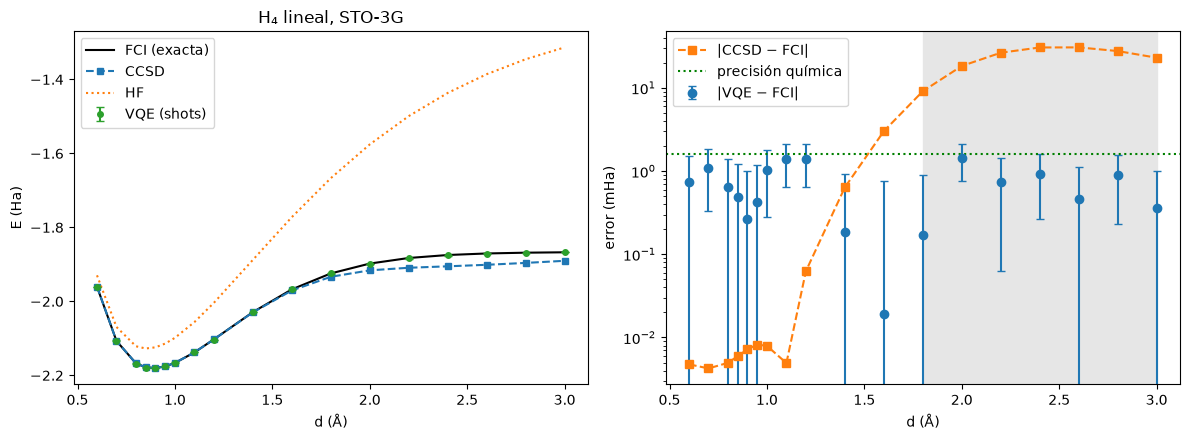

In [13]:
from h4vqe.analysis import plot_curve
fig = plot_curve(df, "curva_h4.png")

In [14]:
from h4vqe.analysis import fit_minimum, dissociation_energy, fci_minimum, compare_fits, DEFAULT_FIT
# Referencia: mínimo FCI verdadero (minimizando PySCF en d), NO un ajuste sobre la grilla.
ref = fci_minimum()
far = df[df.d == df.d.max()].iloc[0]
De_fci = far.E_fci - ref["E_min"]
# Comparación de modelos. "sesgo" = modelo aplicado a FCI en la misma grilla − mínimo verdadero:
# mide el error del método de ajuste, sin mirar el VQE. Con eso elegimos el modelo.
cmp = compare_fits(df, ref)
display(cmp.round(3))
fit = fit_minimum(df.d, df.E_vqe, df.sigma, DEFAULT_FIT)
de = dissociation_energy(far.E_vqe, far.sigma, fit)
print(f"modelo: {fit['model']} sobre d = {fit['fit_points']}")
print(f"R_e (VQE) = {fit['R_e']:.4f} ± {fit['R_e_sigma']:.4f} Å   | R_e (FCI) = {ref['R_e']:.4f} Å   "
      f"→ diferencia {1e3*(fit['R_e']-ref['R_e']):+.1f} mÅ = {(fit['R_e']-ref['R_e'])/fit['R_e_sigma']:+.1f} σ")
print(f"D_e (VQE) = {1e3*de['D_e']:.2f} ± {1e3*de['D_e_sigma']:.2f} mHa | D_e (FCI) = {1e3*De_fci:.2f} mHa  "
      f"→ diferencia {1e3*(de['D_e']-De_fci):+.2f} mHa = {(de['D_e']-De_fci)/de['D_e_sigma']:+.1f} σ")
s = df[df.d >= config.STRETCHED_FROM]
print(f"zona estirada: le gana a CCSD en {int(s.beats_ccsd.sum())}/{len(s)} puntos; precisión química en {int(s.chem_acc.sum())}/{len(s)}")

,modelo,n_puntos,R_e (Å),σ R_e (mÅ),D_e (mHa),σ D_e (mHa),sesgo R_e (mÅ),sesgo E_min (µHa),R_e − R_e(FCI) (mÅ),D_e − D_e(FCI) (mHa)
0,cuadrático 3,3,0.888000,5.463000,313.865000,0.930000,1.755000,66.362000,-0.812000,0.651000
1,cuadrático 5,5,0.893000,2.245000,313.672000,0.944000,7.793000,125.928000,4.795000,0.458000
2,cúbico 6,6,0.884000,2.532000,314.081000,0.807000,-2.067000,-169.819000,-4.992000,0.867000
3,cúbico 7,7,0.886000,2.476000,314.443000,0.775000,0.384000,-575.260000,-2.616000,1.229000
4,cuártico 7,7,0.884000,2.281000,313.917000,0.838000,-0.873000,-15.697000,-4.086000,0.703000
5,cuártico 8,8,0.884000,1.759000,313.868000,0.789000,-1.918000,217.493000,-4.334000,0.653000
6,"spline 0,6–1,6 Å",11,0.886000,7.575000,313.935000,0.922000,-0.510000,-4.759000,-2.211000,0.721000


modelo: cuártico 7 sobre d = [0.7, 0.8, 0.85, 0.9, 0.95, 1.0, 1.1]
R_e (VQE) = 0.8845 ± 0.0023 Å   | R_e (FCI) = 0.8886 Å   → diferencia -4.1 mÅ = -1.7 σ
D_e (VQE) = 313.92 ± 0.85 mHa | D_e (FCI) = 313.21 mHa  → diferencia +0.70 mHa = +0.8 σ
zona estirada: le gana a CCSD en 7/7 puntos; precisión química en 7/7


## 5 · ¿Por qué confiar en la zona estirada?  *(Joaquín)*

La consigna pide argumentar la confiabilidad **antes** de comparar con FCI. Entonces todo lo de esta sección se **mide con shots** (SamplerV2 de Aer) y no usa FCI. FCI aparece recién en la última tabla, como comprobación.

En tres puntos estirados (1,8, 2,4 y 3,0 Å) comparamos tres estados preparados con circuitos: **HF** (θ = 0), **UCCSD ×1** (26 parámetros) y el **ansatz de la curva** (UCCSD ×2, 52 parámetros).

**1. Principio variacional.** Para cualquier estado, E(θ) ≥ E₀, salvo ruido estadístico (±σ). Por eso, entre estados variacionales, el que da la energía más baja es el mejor. CCSD no es variacional: en la zona estirada queda *por debajo* de la exacta, y ahí "más bajo" no quiere decir "mejor".

**2. Varianza de la energía medida por grupos.** En un autoestado, Var(H) = ⟨H²⟩ − ⟨H⟩² = 0. La medimos como ⟨(H−c)²⟩ − (⟨H⟩−c)², con ⟨(H−c)²⟩ medido con el mismo estimador que la energía: (H−c)² tiene 1775 cadenas de Pauli, que se miden en 225 grupos QWC. Tomamos c = término constante de H porque reduce σ a la mitad respecto de c = E.
*Resultado y limitación:* con 2M de shots, σ ≈ 2·10⁻³ Ha². HF da 0,111, 0,149 y 0,176 ± 0,002 Ha² (1,8, 2,4 y 3,0 Å). El ansatz de la curva da (0,5 / 0,2 / 0,9) · 10⁻³ ± 2·10⁻³ Ha², compatible con 0 y al menos 50 veces menos que HF. Como es una resta de números grandes, no llega a separar UCCSD ×1 (~10⁻⁴–10⁻³) de ×2, y por ruido puede dar negativa: en la tabla se muestra recortada en 0, con su σ. Esta medición solo separa HF del resto; la que resuelve es el eco.

**3. Varianza por eco de Loschmidt.** Es la forma fina de medir lo mismo. El circuito prepara ψ, lo evoluciona con e^{−iHt} y lo des-prepara con U(θ)†:

  P(no volver a |0…0⟩) = 1 − |⟨ψ|e^{−iHt}|ψ⟩|² = Var(H)·t² + O(t⁴).

En vez de restar dos números grandes, cuenta **eventos raros**: si ψ es un autoestado, no vuelve ningún shot "mal". Con N shots y 0 eventos, la cota del 95 % es Var ≲ 3/(N t²). Usamos t = 1 Ha⁻¹ y Suzuki-Trotter de 2º orden con 4 pasos. El error de Trotter lo verificamos sin FCI, comparando 2 contra 4 pasos: escala como 1/n⁴ y con 4 pasos es 9·10⁻⁸, debajo de la resolución de 10⁶ shots. A orden dominante, el eco *subestima* Var (Mandelstam-Tamm); a t = 1 la diferencia es ~8 % para UCCSD ×1.
**Resultado:** con 10⁶ shots, el ansatz de la curva tuvo **1 evento a 1,8 Å y ninguno a 2,4 ni a 3,0 Å**, así que Var ≤ 5·10⁻⁶ Ha² en los tres puntos (95 %). Para comparar: HF da 0,11–0,16 Ha² y UCCSD ×1 da 2,8·10⁻³ (1,8 Å), 3,1·10⁻⁴ (2,4 Å) y 1,0·10⁻⁴ Ha² (3,0 Å).
*Costo:* el circuito de eco tiene U(θ), la evolución con Trotter y U(θ)†: entre 4100 y 5700 CZ según el estado (columna `echo_cz`). **Es un diagnóstico de simulador sin ruido, no una propuesta para hardware**: con 0,1 % de error por CZ, el ruido taparía la señal. En hardware, el diagnóstico equivalente es la varianza por grupos, con más shots.
*Qué implica:* por la cota de Weinstein, hay un autovalor exacto de Ĥ a menos de √Var ≤ 2,2 mHa de la energía medida. Si además hay un gap Δ al primer excitado del mismo sector, el error es E − E₀ ≈ Var/Δ, mucho menor que la σ de shots. Que ese autovalor sea el fundamental lo sostienen los puntos 1, 4 y 5: es el estado variacional más bajo que encontramos, tiene las simetrías correctas y no baja más al agregar profundidad.

**4. Simetrías medidas.** H₄ tiene un fundamental singlete con N_α = N_β = 2. Medimos ⟨N_α⟩, ⟨N_β⟩ y ⟨S²⟩ con shots:
- **N_α y N_β dan exactamente 2 en todos los shots**: el ansatz de excitaciones conserva el número de partículas.
- **S² es la prueba que discrimina.** Al estirar, el singlete y el triplete se acercan, y UCCSD ×1 (un solo paso de Trotter, que no está adaptado al espín) converge a una mezcla. Su ⟨S²⟩ medido da 0,64 ± 0,01 a 2,4 Å y 0,85 ± 0,01 a 3,0 Å. A 3,0 Å su energía medida es **indistinguible** de la del ansatz de la curva (−0,2 ± 0,9 mHa): la energía sola no lo delata, la S² medida sí. El ansatz de la curva da |S²| ≤ 0,04 con σ = 0,016 (compatible con 0). Un singlete da 0 y un triplete puro da 2; HF da entre −0,02 y 0,00 ± 0,011, así que la σ alcanza de sobra para separar los casos.

**5. Convergencia con la profundidad.** Al pasar de UCCSD ×1 a ×2, la energía medida baja 3,3 ± 1,0 mHa a 1,8 Å y 1,6 ± 0,9 mHa a 2,4 Å, y no cambia dentro del ruido a 3,0 Å (−0,2 ± 0,9 mHa). La varianza medida por eco cae de 10⁻⁴–10⁻³ Ha² a ≤ 5·10⁻⁶ Ha² en los tres. Por eso la energía sola no alcanza como criterio de convergencia: a 3,0 Å es la varianza (y la S²) la que separa los dos estados. Una varianza ≈ 0 es la firma de un autoestado: si se agregan más parámetros, la energía ya no puede bajar por más que ~Var/Δ.

**6. Barras de error calibradas.** Ver la calibración de σ en la sección de medición (Santino).

> La tabla siguiente reúne todo lo medido. La última celda compara recién ahí con FCI.


In [15]:
from h4vqe.pipeline import run_reliability
# Tres puntos de la zona estirada; en cada uno, HF vs UCCSD ×1 vs el ansatz de la curva.
rel_d = [1.8, 3.0] if QUICK else [1.8, 2.4, 3.0]
t0 = time.time()
rel = pd.DataFrame(run_reliability(ctxs, rel_d, shots=shots,
                                   var_shots=500_000 if QUICK else 2_000_000,
                                   echo_shots=200_000 if QUICK else 1_000_000,
                                   sym_shots=100_000 if QUICK else 200_000))
print(f"total: {time.time()-t0:.0f} s")
# Var(grupos) puede salir negativa por ruido (σ ≈ 2e-3 Ha²): se muestra recortada en 0, con su σ.
# Solo separa HF del resto; la que resuelve es la del eco.
rel["var_grupos (≥0)"] = rel["var"].clip(lower=0)
# echo_cz: CZ del circuito de eco (U, e^{−iHt}, U†). Es un diagnóstico de simulador, no de hardware.
show = rel[["d","estado","cz","E","sigma","var_grupos (≥0)","var_sigma","var_echo","var_echo_up95","echo_events",
            "echo_cz","N_alpha","N_alpha_sigma","N_beta","N_beta_sigma","S2","S2_sigma","var_exacta"]]
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(show)

d=1.80 HF               E=-1.666543±0.59 mHa  Var(grupos)=1.1e-01±2e-03  Var(eco)=1.1e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=-0.000  (19s)


d=1.80 UCCSD ×1 (26 θ)  E=-1.921161±0.71 mHa  Var(grupos)=1.2e-03±3e-03  Var(eco)=2.8e-03 (≤3e-03)  N_α=2.000 N_β=2.000 S²=0.025  (15s)


d=1.80 curva (52 θ)     E=-1.924483±0.72 mHa  Var(grupos)=5.5e-04±3e-03  Var(eco)=1.0e-06 (≤5e-06)  N_α=2.000 N_β=2.000 S²=0.010  (29s)


d=2.40 HF               E=-1.436024±0.60 mHa  Var(grupos)=1.5e-01±2e-03  Var(eco)=1.4e-01 (≤1e-01)  N_α=2.000 N_β=2.000 S²=-0.010  (19s)


d=2.40 UCCSD ×1 (26 θ)  E=-1.873626±0.67 mHa  Var(grupos)=8.2e-04±2e-03  Var(eco)=3.1e-04 (≤3e-04)  N_α=2.000 N_β=2.000 S²=0.638  (18s)


d=2.40 curva (52 θ)     E=-1.875255±0.67 mHa  Var(grupos)=1.8e-04±2e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=-0.037  (28s)


d=3.00 HF               E=-1.313886±0.60 mHa  Var(grupos)=1.8e-01±2e-03  Var(eco)=1.6e-01 (≤2e-01)  N_α=2.000 N_β=2.000 S²=-0.019  (17s)


d=3.00 UCCSD ×1 (26 θ)  E=-1.866665±0.63 mHa  Var(grupos)=-2.9e-04±2e-03  Var(eco)=9.6e-05 (≤1e-04)  N_α=2.000 N_β=2.000 S²=0.851  (17s)


d=3.00 curva (52 θ)     E=-1.866494±0.65 mHa  Var(grupos)=8.9e-04±2e-03  Var(eco)=0.0e+00 (≤3e-06)  N_α=2.000 N_β=2.000 S²=0.003  (29s)
total: 192 s


,d,estado,cz,E,sigma,var_grupos (≥0),var_sigma,var_echo,var_echo_up95,echo_events,echo_cz,N_alpha,N_alpha_sigma,N_beta,N_beta_sigma,S2,S2_sigma,var_exacta
0,1.8,HF,292,-1.67,0.000585,0.111,0.00206,0.108,0.109,108066,4130,2,0,2,0,-0.000374,0.011,0.115
1,1.8,UCCSD ×1 (26 θ),292,-1.92,0.000715,0.0012,0.00283,0.00279,0.00288,2792,4574,2,0,2,0,0.0249,0.0151,0.00303
2,1.8,curva (52 θ),582,-1.92,0.000717,0.000546,0.00285,1e-06,4.74e-06,1,5674,2,0,2,0,0.0103,0.0153,1.37e-10
3,2.4,HF,292,-1.44,0.000597,0.149,0.0017,0.139,0.139,138768,4130,2,0,2,0,-0.00983,0.0109,0.148
4,2.4,UCCSD ×1 (26 θ),292,-1.87,0.00067,0.000822,0.00246,0.000306,0.000336,306,4902,2,0,2,0,0.638,0.0143,0.000381
5,2.4,curva (52 θ),582,-1.88,0.000666,0.000181,0.00237,0,3e-06,0,5674,2,0,2,0,-0.037,0.016,7.82e-10
6,3,HF,292,-1.31,0.000604,0.176,0.00153,0.163,0.164,163464,4130,2,0,2,0,-0.0185,0.011,0.176
7,3,UCCSD ×1 (26 θ),292,-1.87,0.000633,0,0.00216,9.6e-05,0.000114,96,4902,2,0,2,0,0.851,0.0131,9.53e-05
8,3,curva (52 θ),582,-1.87,0.000651,0.000886,0.00214,0,3e-06,0,5674,2,0,2,0,0.0025,0.016,3.32e-10


In [16]:
# Convergencia con la profundidad (sin FCI): cuánto baja la energía MEDIDA al agregar
# parámetros, y cuánto cae la varianza (eco) en el mismo paso.
piv = rel.pivot(index="d", columns="estado", values="E")
lbl = [c for c in piv.columns if c.startswith("curva")][0]
lbl1 = [c for c in piv.columns if c.startswith("UCCSD")][0]
sig = rel.pivot(index="d", columns="estado", values="sigma")
conv = pd.DataFrame({
    "E(×1) − E(curva) [mHa]": 1e3*(piv[lbl1] - piv[lbl]),
    "σ [mHa]": 1e3*np.hypot(sig[lbl1], sig[lbl]),
    "Var eco ×1 [Ha²]": rel[rel.estado == lbl1].set_index("d").var_echo,
    "Var eco curva ≤ [Ha²] (95 %)": rel[rel.estado == lbl].set_index("d").var_echo_up95,
})
with pd.option_context("display.float_format", lambda v: f"{v:.3g}"):
    display(conv)
# Recién ahora, como comprobación: el error real contra FCI.
chk = df.set_index("d").loc[rel_d, ["err_vqe_mHa", "sigma_mHa", "err_ccsd_mHa"]]
chk

,E(×1) − E(curva) [mHa],σ [mHa],Var eco ×1 [Ha²],Var eco curva ≤ [Ha²] (95 %)
d,,,,
1.8,3.32,1.01,0.00279,4.74e-06
2.4,1.63,0.945,0.000306,3e-06
3,-0.171,0.908,9.6e-05,3e-06


,err_vqe_mHa,sigma_mHa,err_ccsd_mHa
d,,,
1.800000,0.171780,0.717019,9.107638
2.400000,0.931115,0.666610,30.559966
3.000000,0.361289,0.651056,23.013003


## 6 · Extras

> TODO: cada extra en su subsección, con su dueño. Ruido (`ruido.py`: cz 0,1 %, 1q 0,005 %, línea), ZNE, lectura, 6 qubits, comparar ansätze.


## 7 · Qué decidimos, qué no funcionó y limitaciones

| decisión | por qué | alternativa descartada |
|---|---|---|
| UCCSD ×2 | exacto en toda la curva | hardware-efficient: difícil de optimizar, rompe N |
| optimizar sin ruido | permitido; mucho más rápido | SPSA con shots: lento y ruidoso |
| SamplerV2 + σ propia | barras honestas, permite Neyman | EstimatorV2 con `precision`: σ fija |
| R_e con cuártico en 7 puntos (0,7–1,1 Å) | sesgo < 1 mÅ al aplicarlo a FCI en la misma grilla | cuadrático en 5 puntos: sesgo de +8 mÅ, mayor que σ |
| referencia R_e(FCI) minimizando PySCF | compara el VQE contra la verdad, no contra otro ajuste | ajustar FCI con el mismo modelo (esconde el sesgo del ajuste) |
| varianza por eco de Loschmidt | cuenta eventos raros: resuelve Var ~ 10⁻⁶ Ha² con 1M shots | solo ⟨H²⟩ por grupos QWC: σ ≈ 3·10⁻³ Ha² (no separa ×1 de ×2) |

**Qué no funcionó:**
- Semillas consecutivas en el Sampler ⇒ σ subestimada (corregido).
- La misma semilla en las 18 distancias ⇒ ruido de shots correlacionado entre puntos vecinos (detectado por Gonzalo: ~3σ seguidos en 0,7–0,9 Å con 200 k shots). Eso sesga el ajuste de R_e y hace que su σ de Monte Carlo, que supone errores independientes, quede chica. Ahora cada punto y cada diagnóstico usa su propia semilla, separadas por un paso de 1000 para que no choquen con las semillas derivadas del estimador (seed+1 de la etapa de Neyman).
- Medir la varianza como ⟨H²⟩ − ⟨H⟩² con grupos QWC: (H−c)² tiene 1775 Paulis en 225 grupos y cada grupo fluctúa mucho aunque el total sea ≈ 0, así que la σ queda en ~10⁻³ Ha² aunque se usen millones de shots. Restar la constante de H (c) reduce σ a la mitad, pero no alcanza. Lo dejamos como medición directa y sumamos el eco.
- Eco con 2 pasos de Trotter: el error de Trotter (1,3·10⁻⁶) se confundía con la señal. Con 4 pasos baja a 9·10⁻⁸.

> TODO (todos): agregar lo que vayan probando.
